In [34]:
# Importing the required libraries, modules, and classes

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from babel.plural import negate

from sklearn.datasets import fetch_california_housing
from sklearn.model_selection import train_test_split, cross_val_score, GridSearchCV
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression, Ridge, ridge_regression
from sklearn.tree import DecisionTreeRegressor
from sklearn.metrics import mean_squared_error, root_mean_squared_error, r2_score

import joblib

In [2]:
# Loading the dataset and creating a Pandas dataframe

data = fetch_california_housing(as_frame=True)
df = pd.concat([data.data, data.target.rename('HousePrice')], axis=1)

In [3]:
# Getting the dataset description

print(data['DESCR'])

.. _california_housing_dataset:

California Housing dataset
--------------------------

**Data Set Characteristics:**

:Number of Instances: 20640

:Number of Attributes: 8 numeric, predictive attributes and the target

:Attribute Information:
    - MedInc        median income in block group
    - HouseAge      median house age in block group
    - AveRooms      average number of rooms per household
    - AveBedrms     average number of bedrooms per household
    - Population    block group population
    - AveOccup      average number of household members
    - Latitude      block group latitude
    - Longitude     block group longitude

:Missing Attribute Values: None

This dataset was obtained from the StatLib:
https://lib.stat.cmu.edu/datasets/houses.zip

The target variable is the median house value for California districts,
expressed in hundreds of thousands of dollars ($100,000).

This dataset was derived from the 1990 U.S. census, using one row per census
block group. A block g

In [4]:
# Checking the dataframe columns

print("\nColumns Present:")
print(df.columns)

# Checking the data type of each column
print("\nData Types:")
print(df.dtypes)

# Checking for missing values
print("\nMising Values:")
print(df.isnull().sum())



Columns Present:
Index(['MedInc', 'HouseAge', 'AveRooms', 'AveBedrms', 'Population', 'AveOccup',
       'Latitude', 'Longitude', 'HousePrice'],
      dtype='str')

Data Types:
MedInc        float64
HouseAge      float64
AveRooms      float64
AveBedrms     float64
Population    float64
AveOccup      float64
Latitude      float64
Longitude     float64
HousePrice    float64
dtype: object

Mising Values:
MedInc        0
HouseAge      0
AveRooms      0
AveBedrms     0
Population    0
AveOccup      0
Latitude      0
Longitude     0
HousePrice    0
dtype: int64


In [5]:
# Statistical Summary of the dataset

print(df.describe())

             MedInc      HouseAge      AveRooms     AveBedrms    Population  \
count  20640.000000  20640.000000  20640.000000  20640.000000  20640.000000   
mean       3.870671     28.639486      5.429000      1.096675   1425.476744   
std        1.899822     12.585558      2.474173      0.473911   1132.462122   
min        0.499900      1.000000      0.846154      0.333333      3.000000   
25%        2.563400     18.000000      4.440716      1.006079    787.000000   
50%        3.534800     29.000000      5.229129      1.048780   1166.000000   
75%        4.743250     37.000000      6.052381      1.099526   1725.000000   
max       15.000100     52.000000    141.909091     34.066667  35682.000000   

           AveOccup      Latitude     Longitude    HousePrice  
count  20640.000000  20640.000000  20640.000000  20640.000000  
mean       3.070655     35.631861   -119.569704      2.068558  
std       10.386050      2.135952      2.003532      1.153956  
min        0.692308     32.54000

array([[<Axes: title={'center': 'MedInc'}>,
        <Axes: title={'center': 'HouseAge'}>,
        <Axes: title={'center': 'AveRooms'}>],
       [<Axes: title={'center': 'AveBedrms'}>,
        <Axes: title={'center': 'Population'}>,
        <Axes: title={'center': 'AveOccup'}>],
       [<Axes: title={'center': 'Latitude'}>,
        <Axes: title={'center': 'Longitude'}>,
        <Axes: title={'center': 'HousePrice'}>]], dtype=object)

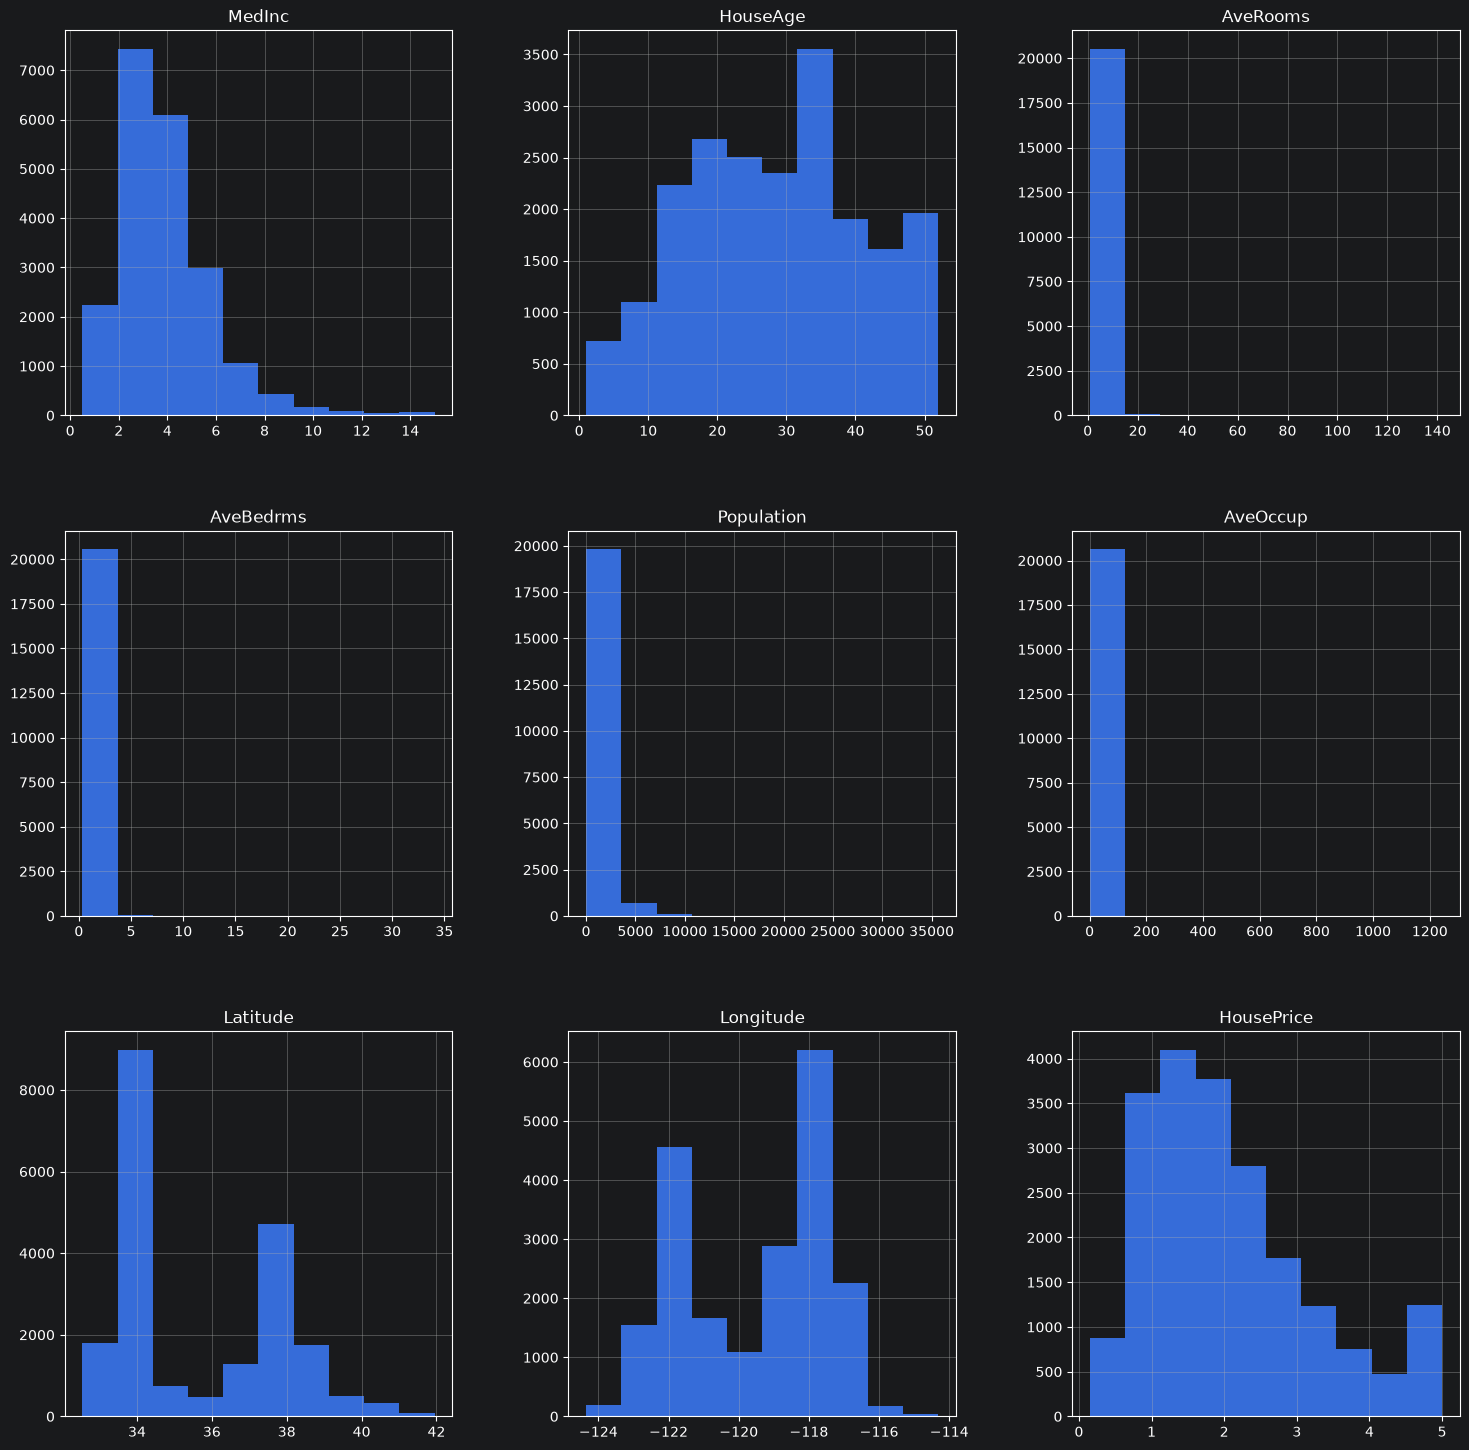

In [6]:
# Checking class distribution of each column
df.hist(figsize= (18,18))

In [7]:
# Correlation Analysis of the dataset

corr_matrix = df.corr()
print(corr_matrix)

              MedInc  HouseAge  AveRooms  AveBedrms  Population  AveOccup  \
MedInc      1.000000 -0.119034  0.326895  -0.062040    0.004834  0.018766   
HouseAge   -0.119034  1.000000 -0.153277  -0.077747   -0.296244  0.013191   
AveRooms    0.326895 -0.153277  1.000000   0.847621   -0.072213 -0.004852   
AveBedrms  -0.062040 -0.077747  0.847621   1.000000   -0.066197 -0.006181   
Population  0.004834 -0.296244 -0.072213  -0.066197    1.000000  0.069863   
AveOccup    0.018766  0.013191 -0.004852  -0.006181    0.069863  1.000000   
Latitude   -0.079809  0.011173  0.106389   0.069721   -0.108785  0.002366   
Longitude  -0.015176 -0.108197 -0.027540   0.013344    0.099773  0.002476   
HousePrice  0.688075  0.105623  0.151948  -0.046701   -0.024650 -0.023737   

            Latitude  Longitude  HousePrice  
MedInc     -0.079809  -0.015176    0.688075  
HouseAge    0.011173  -0.108197    0.105623  
AveRooms    0.106389  -0.027540    0.151948  
AveBedrms   0.069721   0.013344   -0.046701  

Text(0.5, 1.0, 'Correlation Heatmap')

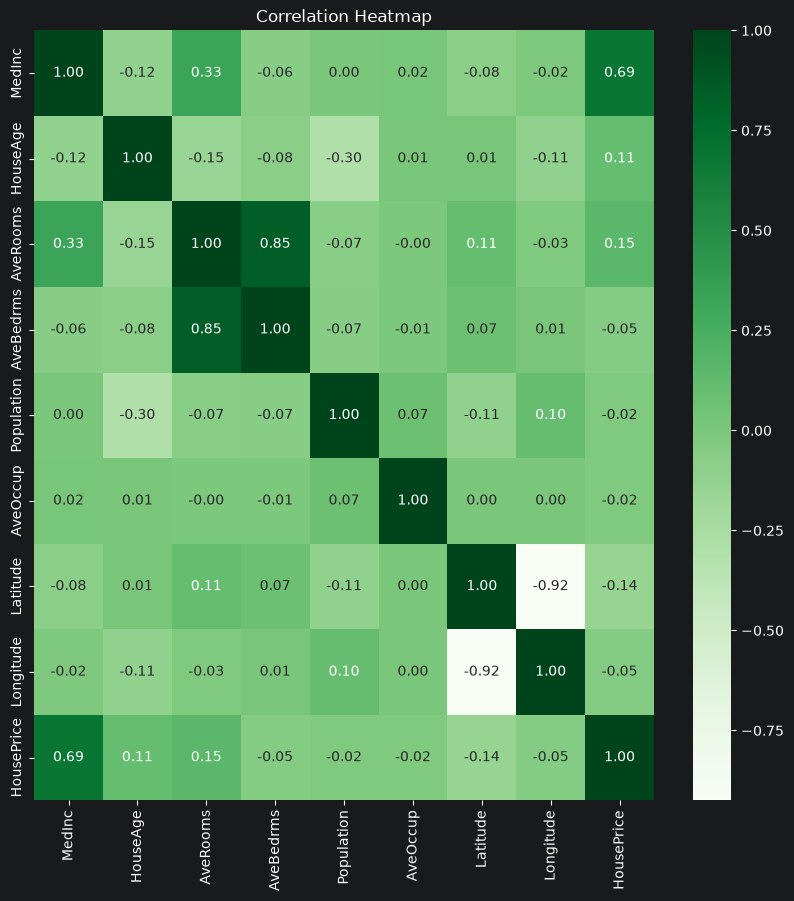

In [8]:
# Generating heatmap from the correlation matrix

plt.figure(figsize=(10,10))
sns.heatmap(df.corr(), annot=True, cmap="Greens", fmt=".2f")
plt.title("Correlation Heatmap")

In [9]:
# Separating Features and Target

X = df.drop("HousePrice", axis=1)
y = df["HousePrice"]


In [22]:
# Train test split and Feature Scaling using Standard Scaler
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

In [39]:
# Training Linear Regression Model

linReg = LinearRegression()
linReg.fit(X_train_scaled, y_train)

linReg_Predict = linReg.predict(X_test_scaled)

linReg_rmse = np.sqrt(mean_squared_error(y_test, linReg_Predict))
linReg_r2 = r2_score(y_test, linReg_Predict)

In [46]:
# Training Decision Tree and comparing the RMSE for training and test sets for detection of overfitting

decTree = DecisionTreeRegressor(random_state=42)
decTree.fit(X_train_scaled, y_train)

tree_train_predictions = decTree.predict(X_train_scaled)
tree_test_predictions = decTree.predict(X_test_scaled)

tree_r2 = r2_score(y_test, tree_test_predictions)

tree_train_mse = mean_squared_error(y_train, train_predictions)
tree_test_mse = mean_squared_error(y_test, test_predictions)

tree_train_mse, tree_test_mse

(9.105916214578782e-32, 0.4930463021407461)

In [43]:
# Training Ridge Regression model and checking for overfitting

ridgeModel = Ridge(alpha=0.1)
ridgeModel.fit(X_train_scaled, y_train)

ridge_train_predictions = ridgeModel.predict(X_train_scaled)
ridge_test_predictions = ridgeModel.predict(X_test_scaled)

ridge_r2 = r2_score(y_test, ridge_test_predictions)

ridge_train_mse = mean_squared_error(y_train, train_predictions)
ridge_test_mse = mean_squared_error(y_test, test_predictions)

ridge_r2, ridge_train_mse, ridge_test_mse

(0.5757905180002314, 9.105916214578782e-32, 0.4930463021407461)

In [28]:
# Cross Validation Score for Decision tree

cv_scores = cross_val_score(decTree, X_train_scaled, y_train, scoring= "neg_root_mean_squared_error", cv=5)

cv_rmse = -cv_scores.mean()
cv_rmse

np.float64(0.7246628018613701)

In [32]:
# Hyperparameter Tuning of Decision Tree Model using GridSeacrhCV

param_grid={
    "max_depth":[3,5,7,10],
    "min_samples_split":[2,5, 10]
}

decTree_grid = GridSearchCV(
    DecisionTreeRegressor(random_state=42),
    param_grid=param_grid,
    scoring="neg_root_mean_squared_error",
    cv=5
)

decTree_grid.fit(X_train_scaled, y_train)

decTree_grid.best_params_

{'max_depth': 10, 'min_samples_split': 10}

In [44]:
# Evaluating Optimized Tree Model

optimizedTree = decTree_grid.best_estimator_

optimumTree_X_pred = optimizedTree.predict(X_test_scaled)

optimumTree_rmse = np.sqrt(mean_squared_error(y_test, otimumTree_X_pred))
optimumTree_r2 = r2_score(y_test, otimumTree_X_pred)

optimumTree_rmse, optimumTree_r2

(np.float64(0.6453626634464059), 0.6821656640892819)

In [49]:
# Storing the result

results = {
    'Models':["Linear Regression", "Ridge Regression", "Decision Tree Regression", "Tuned Decision Tree"],

    "RMSE":[linReg_rmse, np.sqrt(ridge_test_mse), np.sqrt(tree_test_mse), optimumTree_rmse],
    "R2 Score":[linReg_r2, ridge_r2, tree_r2, optimumTree_r2]
}

results_df = pd.DataFrame(results)

In [52]:
# Save cross-validation results for Decision Tree and Ridge

cv_results_df = pd.DataFrame({
    "Fold": [1, 2, 3, 4, 5],
    "Decision Tree RMSE": -cv_scores,
    "Ridge Regression RMSE": -ridge_cv
})

# Add the average RMSE
cv_results_df.loc["Mean"] = [
    "Mean",
    cv_results_df["Decision Tree RMSE"].iloc[:5].mean(),
    cv_results_df["Ridge Regression RMSE"].iloc[:5].mean()
]

cv_results_df.to_csv("CrossValidationResults.csv", index=False)

print(cv_results_df)
print("Cross-validation results saved!")


      Fold  Decision Tree RMSE  Ridge Regression RMSE
0        1            0.753029               0.721156
1        2            0.712178               0.708726
2        3            0.712136               0.721489
3        4            0.744136               0.712669
4        5            0.701835               0.738596
Mean  Mean            0.724663               0.720527
Cross-validation results saved!


In [53]:
# Extract all hyperparameter tuning results

tuning_results_df = pd.DataFrame(decTree_grid.cv_results_)

# Keep the most useful columns
tuning_results_df = tuning_results_df[
    [
        "param_max_depth",
        "param_min_samples_split",
        "mean_test_score",
        "std_test_score",
        "rank_test_score"
    ]
].copy()

# Convert negative RMSE scores into positive RMSE
tuning_results_df["mean_test_RMSE"] = (
    -tuning_results_df["mean_test_score"]
)

tuning_results_df["std_test_RMSE"] = (
    tuning_results_df["std_test_score"]
)

# Remove the original negative-score columns
tuning_results_df.drop(
    columns=["mean_test_score", "std_test_score"],
    inplace=True
)

# Sort by best performance
tuning_results_df.sort_values(
    "rank_test_score", inplace=True
)

# Save results
tuning_results_df.to_csv(
    "HyperparameterTuningResults.csv",
    index=False
)

print(tuning_results_df)
print("\nBest parameters:", decTree_grid.best_params_)
print("Best CV RMSE:", -decTree_grid.best_score_)
print("Hyperparameter tuning results saved!")


    param_max_depth  param_min_samples_split  rank_test_score  mean_test_RMSE  \
11               10                       10                1        0.636817   
10               10                        5                2        0.638027   
9                10                        2                3        0.642460   
6                 7                        2                4        0.652760   
7                 7                        5                5        0.653127   
8                 7                       10                6        0.653482   
3                 5                        2                7        0.712696   
4                 5                        5                7        0.712696   
5                 5                       10                9        0.712722   
1                 3                        5               10        0.795664   
2                 3                       10               10        0.795664   
0                 3         

In [51]:
# Saving the tuned Decision Tree Model

joblib.dump(optimizedTree, "decisionTreeModel.pkl")


['decisionTreeModel.pkl']

In [50]:
# Extracting the results table

with open('ComparisonTable.txt', 'w') as f:
    f.write(results_df.to_string())
    f.close()